In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests
from matplotlib.patches import Patch

In [3]:
# Load expression matrix and metadata
expr_matrix = pd.read_csv('./data/processed/GSE149507_filtered_expression_matrix_final.csv', index_col=0)
metadata = pd.read_csv('./data/processed/GSE149507_filtered_metadata_final.csv', index_col=0)

print(expr_matrix.shape)
print(metadata['group'].value_counts())

(20172, 28)
group
SCLC      14
Normal    14
Name: count, dtype: int64


In [5]:
# For paired test - order matters!
sclc_samples = metadata[metadata['group'] == 'SCLC'].index.tolist()
normal_samples = metadata[metadata['group'] == 'Normal'].index.tolist()

print("SCLC samples:")
print(sclc_samples)
print("\nNormal samples:")
print(normal_samples)

SCLC samples:
['GSM4504101', 'GSM4504103', 'GSM4504105', 'GSM4504107', 'GSM4504111', 'GSM4504113', 'GSM4504119', 'GSM4504121', 'GSM4504123', 'GSM4504125', 'GSM4504127', 'GSM4504131', 'GSM4504133', 'GSM4504135']

Normal samples:
['GSM4504102', 'GSM4504104', 'GSM4504106', 'GSM4504108', 'GSM4504112', 'GSM4504114', 'GSM4504120', 'GSM4504122', 'GSM4504124', 'GSM4504126', 'GSM4504128', 'GSM4504132', 'GSM4504134', 'GSM4504136']


In [7]:
from scipy.stats import wilcoxon

results = []

for gene in expr_matrix.index:
    sclc_values = expr_matrix.loc[gene, sclc_samples].values
    normal_values = expr_matrix.loc[gene, normal_samples].values
    
    # Calculate differences for paired test
    differences = sclc_values - normal_values
    
    # Skip if all differences are zero
    if np.all(differences == 0):
        results.append({'Gene': gene, 'log2FC': 0, 'pvalue': 1.0})
        continue
    
    # Wilcoxon signed-rank test
    stat, pval = wilcoxon(differences)
    
    # Log2 fold change
    log2fc = np.mean(differences)
    
    results.append({'Gene': gene, 'log2FC': log2fc, 'pvalue': pval})

# Convert to dataframe
results_df = pd.DataFrame(results).set_index('Gene')

# BH correction
reject, pvals_corrected, _, _ = multipletests(results_df['pvalue'], method='fdr_bh')
results_df['padj'] = pvals_corrected

print(results_df.shape)
print(results_df.head())

D:\Anaconda\Lib\site-packages\scipy\stats\_morestats.py:4088: UserWarning: Exact p-value calculation does not work if there are zeros. Switching to normal approximation.
  warnings.warn("Exact p-value calculation does not work if there are "
D:\Anaconda\Lib\site-packages\scipy\stats\_morestats.py:4088: UserWarning: Exact p-value calculation does not work if there are zeros. Switching to normal approximation.
  warnings.warn("Exact p-value calculation does not work if there are "
D:\Anaconda\Lib\site-packages\scipy\stats\_morestats.py:4088: UserWarning: Exact p-value calculation does not work if there are zeros. Switching to normal approximation.
  warnings.warn("Exact p-value calculation does not work if there are "
D:\Anaconda\Lib\site-packages\scipy\stats\_morestats.py:4088: UserWarning: Exact p-value calculation does not work if there are zeros. Switching to normal approximation.
  warnings.warn("Exact p-value calculation does not work if there are "
D:\Anaconda\Lib\site-packages\sc

(20172, 3)
            log2FC    pvalue      padj
Gene                                  
A1BG      0.724581  0.004028  0.010622
A1BG-AS1  0.180603  0.067627  0.116149
A1CF      0.054363  0.625732  0.711194
A2M      -1.709850  0.000122  0.000790
A2M-AS1  -1.565374  0.000122  0.000790


D:\Anaconda\Lib\site-packages\scipy\stats\_morestats.py:4088: UserWarning: Exact p-value calculation does not work if there are zeros. Switching to normal approximation.
  warnings.warn("Exact p-value calculation does not work if there are "


In [9]:
# Strict filter
sig_degs = results_df[(results_df['padj'] < 0.05) & (abs(results_df['log2FC']) >= 1)]
print(f"Total significant DEGs: {len(sig_degs)}")
print(f"Upregulated: {(sig_degs['log2FC'] > 0).sum()}")
print(f"Downregulated: {(sig_degs['log2FC'] < 0).sum()}")

# Stats only
sig_stats_only = results_df[results_df['padj'] < 0.05]
print(f"\nStatistically significant (no FC filter): {len(sig_stats_only)}")

Total significant DEGs: 3145
Upregulated: 1398
Downregulated: 1747

Statistically significant (no FC filter): 10118


In [11]:
results_df.to_csv('./results/DEG/GSE149507_DEG_results.csv')
sig_stats_only.to_csv('./results/DEG/GSE149507_DEG_results_stats_only.csv')
sig_degs.to_csv('./results/DEG/GSE149507_DEG_results_strict.csv')

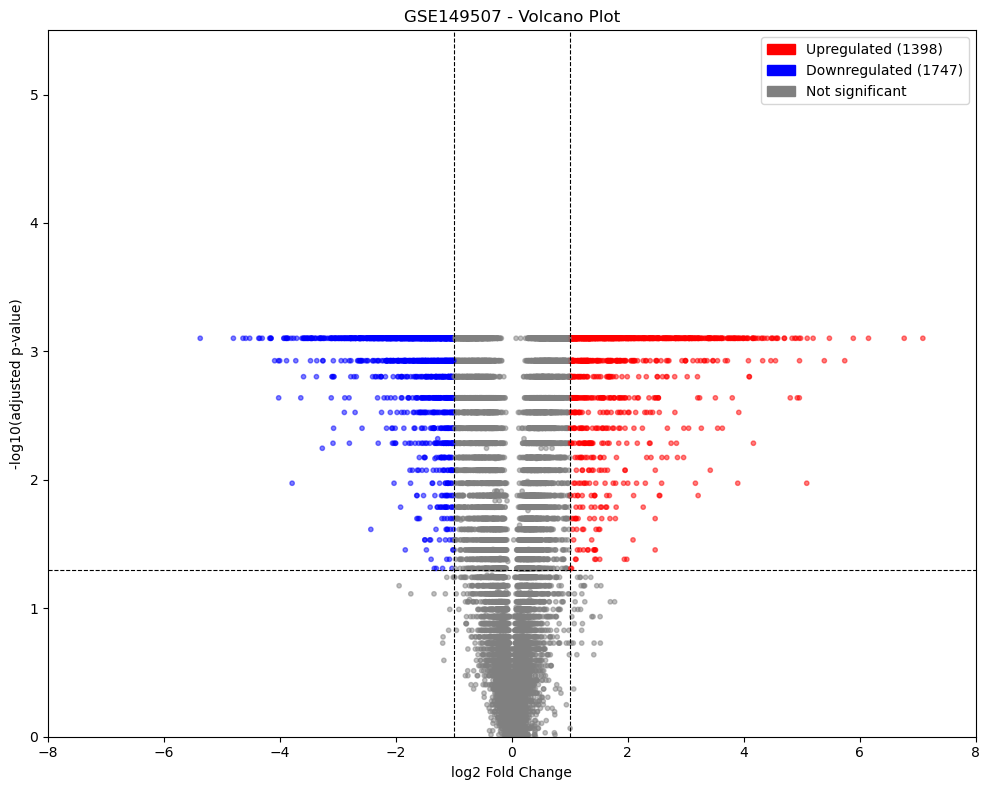

In [17]:
plt.figure(figsize=(10, 8))

colors = []
for idx, row in results_df.iterrows():
    if row['padj'] < 0.05 and row['log2FC'] >= 1:
        colors.append('red')
    elif row['padj'] < 0.05 and row['log2FC'] <= -1:
        colors.append('blue')
    else:
        colors.append('grey')

plt.scatter(results_df['log2FC'], 
            -np.log10(results_df['padj']), 
            c=colors, alpha=0.5, s=10)

plt.axhline(-np.log10(0.05), color='black', linestyle='--', linewidth=0.8)
plt.axvline(1, color='black', linestyle='--', linewidth=0.8)
plt.axvline(-1, color='black', linestyle='--', linewidth=0.8)

plt.xlabel('log2 Fold Change')
plt.ylabel('-log10(adjusted p-value)')
plt.title('GSE149507 - Volcano Plot')

plt.ylim(0, 5.5)
plt.xlim(-8, 8)

legend = [Patch(color='red', label=f'Upregulated ({(sig_degs["log2FC"] > 0).sum()})'),
          Patch(color='blue', label=f'Downregulated ({(sig_degs["log2FC"] < 0).sum()})'),
          Patch(color='grey', label='Not significant')]
plt.legend(handles=legend)

plt.tight_layout()
plt.savefig('./figures/GSE149507_volcano.png', dpi=150)
plt.show()